# Building the Pool Reactor Loop

This page builds the pool reactor of the loss-of-flow examples by hand, one part at a time: the core, the junctions with the pool and the flapper, the pipes, the decay tank and the two pump legs, the flow graph that joins them, the fuel plates on their channels, a first steady solve, and finally the point kinetics. Every cell calls the library's constructors with the arguments the shipped example uses, so the loop built here is the same loop.

The example package `stream.examples.lofa` does all of this in one call, `build`, and the next pages use that call. This page shows what is behind it, in the order one would put a system like this together.

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc

rc("font", family="serif", size=15)

from stream.aggregator import CalculationGraph
from stream.analysis.report import report
from stream.calculations import (
    Bend,
    Channel,
    Flapper,
    Friction,
    Gravity,
    HeatExchanger,
    Inertia,
    Junction,
    KirchhoffWDerivatives,
    Pump,
)
from stream.calculations.flapper import continuously_differentiable_relaxation
from stream.calculations.point_kinetics import PointKineticsWInput, ReactivityController
from stream.composition import (
    FlowGraph,
    ResistorFromKnownPoint,
    check_gravity_mismatch,
    flow_edge,
    point_kinetics_steady_state,
    symmetric_plate,
)
from stream.examples.lofa import Params, build, draw, steady, steady_checks
from stream.examples.lofa.components import CheckValve, LowFlowTrip, horizontal_pressure
from stream.examples.lofa.params import (
    BETA,
    CORE,
    FUEL_N,
    GENERATION_TIME,
    HEATED,
    LAMBDA,
    LENGTH,
    PER_PLATE_REFERENCE,
    PIPE1_DROP,
    Z_N,
    nominal_flows,
    power_share,
)
from stream.examples.lofa.system import decay_heat, make_channel, make_fuel
from stream.physical_models.pressure_drop import pressure_diff
from stream.pipe_geometry import EffectivePipe
from stream.state import State
from stream.substances import light_water
from stream.units import g
from stream.utilities import identity

p = Params()
nominal = nominal_flows(p)
total = nominal["total"]
P0 = p.power * p.power_scale
print(f"core power {P0 / 1e6:.0f} MW, nominal core flow {total:.1f} kg/s")

core power 10 MW, nominal core flow 241.5 kg/s


## Core channels and plates

The core has four groups of plates: one hot plate, 300 normal plates, 90 low-power plates and 10 wider unheated bypass channels. Plates of a group behave alike, so each group is modelled once: one channel and, for the heated groups, one plate. Later, in the flow graph, the group's edge carries the plate count as its `signify` weight, so the junctions see one channel's flow times the number of plates.

The example package provides two short constructors for the core. `make_channel` lays 10 axial cells along the 0.7 m plate, takes the channel's geometry from `plate_pipe` (a rectangle 70 mm wide with the coolant gap as its depth, heated on both wide sides) and returns a `ChannelAndContacts` for a heated group, which exchanges heat with walls on both sides, or a plain `Channel` for the bypass. With `p.friction == "regime"` it gives the channel a friction factor that blends the laminar and turbulent laws between Reynolds numbers 2000 and 5000. `stop_at_saturation` makes a heated channel end a transient with a named error once its coolant reaches saturation, the edge of what the single-phase model can describe.

`make_fuel` builds one plate as a `Fuel`: 10 axial cells, eight meat cells between two cladding cells on each side, and a cosine power shape along the plate. Its `share` scales that shape so the plate takes its fraction of the core power: the group's peaking factor over the sum of plate count times peaking factor, $1.6 / (1 \cdot 1.6 + 300 \cdot 1.0 + 90 \cdot 0.5)$ for the hot plate.

In [2]:
channels = {
    "hot": make_channel("HotChannel", p.gap_hot, True, p.friction, p.stop_at_saturation),
    "normal": make_channel("NormalChannel", CORE["normal"].gap, True, p.friction, p.stop_at_saturation),
    "low": make_channel("LowChannel", CORE["low"].gap, True, p.friction, p.stop_at_saturation),
    "bypass": make_channel("BypassChannel", CORE["bypass"].gap, False, p.friction, p.stop_at_saturation),
}
fuels = {
    "hot": make_fuel("HotFuel", share=power_share("hot")),
    "normal": make_fuel("NormalFuel", share=power_share("normal")),
    "low": make_fuel("LowFuel", share=power_share("low")),
}
print(channels["hot"].pipe)
print(f"hot plate share of the core power: {power_share('hot'):.5f}")

EffectivePipe(length=0.7, heated_perimeter=0.14, wet_perimeter=0.1444, area=0.00015400000000000003, heated_parts=(0.07, 0.07), width=0.07, depth=0.0022, heated_diameter=0.0044, hydraulic_diameter=0.004265927977839336)
hot plate share of the core power: 0.00462


## Junctions, pool and flapper

Seven junctions hold the loop together: the top and bottom of the pool, the plenum under the core, the inlet and outlet of the decay tank, and the split and merge of the two pump legs.

The pool beside the core is a square column of water as tall as the core and holding 300 m³, so its side is about 21 m. It is a plain `Channel` with 10 cells, built from an `EffectivePipe.rectangular` square. Its edge will run from the pool bottom to the pool top, so positive flow in it goes upward; `pressure_diff`, the channels' pressure law, takes positive flow as downward, so the pool gets it with gravity reversed.

The flapper joins the pool bottom to the plenum. It stays shut while the flow returning from the heat exchanger is above `p.flapper_fraction` (30 %) of the nominal core flow and opens below it, then behaves as a local loss of coefficient 5 over 0.05 m². A flapper stuck shut is modelled by an opening threshold no flow can reach.

The trip sensor `LowFlowTrip` is a calculation the example package adds: it watches the same returning flow, latches at 85 % of nominal, and half a second later inserts the rods, worth 10 dollars, over one second. Its worth is given in absolute reactivity, the dollars times the total delayed-neutron fraction.

In [3]:
j_top, j_plenum, j_bot = Junction(name="J_pool_top"), Junction(name="J_plenum"), Junction(name="J_pool_bot")
j_tank_in, j_tank_out = Junction(name="J_tank_in"), Junction(name="J_tank_out")
j_split, j_merge = Junction(name="J_split"), Junction(name="J_merge")

pool_edge = np.sqrt(p.pool_volume * p.pool_area_scale / LENGTH)
pool = Channel(
    z_boundaries=np.linspace(0.0, LENGTH, 11),
    fluid=light_water,
    pipe=EffectivePipe.rectangular(length=LENGTH, edge1=pool_edge, edge2=pool_edge, heated_edge=pool_edge),
    pressure_func=partial(pressure_diff, g=-g),
    name="Pool",
)
flapper = Flapper(
    open_at_current=(-1e9 if p.flapper_stuck else p.flapper_fraction * total),
    f=p.flapper_f,
    fluid=light_water,
    area=p.flapper_area,
    open_rate=1.0,
    stop_on_open=False,
    relaxation=continuously_differentiable_relaxation,
    name="Flapper",
)
trip = LowFlowTrip(
    threshold=p.trip_threshold * total,
    delay=p.trip_delay,
    worth=p.rod_worth_dollars * float(np.sum(BETA)),
    duration=p.rod_duration,
    name="Trip",
)
print(f"pool side {pool_edge:.1f} m, flapper opens below {p.flapper_fraction * total:.1f} kg/s, trip at {p.trip_threshold * total:.1f} kg/s")

pool side 20.7 m, flapper opens below 72.5 kg/s, trip at 205.3 kg/s


## Pipes, tank and pump legs

The library has no single pipe constructor; a pipe is a `Friction` for its wall friction, one `Bend` per elbow, and a `Gravity` for its change of height. The function below assembles those three for a 0.4 m pipe; it is the same as the example package's private helper `_pipe_parts`. Three pipes use it: the primary pipe from the plenum down 4.3 m to the decay tank, with two elbows; the basement pipe down the remaining 3 m to the pumps, with one; and the riser, 7.3 m back up from the heat exchanger to the pool bottom, with two. A positive `disposition` is a drop along the flow, so the riser's is negative.

The decay tank holds 20 m³ in a horizontal square column 5 m long; `horizontal_pressure` is `pressure_diff` without gravity.

Each pump leg is four components in series. The `Pump` imposes half the nominal core flow and leaves its head to the solve. A `ResistorFromKnownPoint` gives the pump its curve: a parabolic loss that takes 60 % of the estimated loop head at the nominal leg flow, so the head falls as the flow rises. The `Inertia` is the flywheel, which carries the flow on after the pump loses its drive. The `CheckValve`, added by the example package, is a quadratic loss forward and a hundred thousand times stiffer backward, so a stopped leg does not carry reverse flow.

The heat exchanger returns the water at 38 °C, and a second `ResistorFromKnownPoint` gives it its 0.5 bar loss at the nominal core flow.

In [4]:
def pipe_parts(tag, length, drop, bends):
    area = np.pi * p.pipe_diameter**2 / 4
    parts = [Friction(f=p.pipe_friction, fluid=light_water, length=length, hydraulic_diameter=p.pipe_diameter,
                      area=area, name=f"Friction{tag}")]
    parts += [Bend(fluid=light_water, hydraulic_diameter=p.pipe_diameter, area=area, bend_radius=1.5 * p.pipe_diameter,
                   bend_angle=np.pi / 2, name=f"Bend{tag}{i}") for i in range(bends)]
    parts.append(Gravity(fluid=light_water, disposition=drop, name=f"Gravity{tag}"))
    return parts


primary = pipe_parts("Primary", PIPE1_DROP, PIPE1_DROP, 2)
basement = pipe_parts("Basement", p.basement_drop - PIPE1_DROP, p.basement_drop - PIPE1_DROP, 1)

tank_length = 5.0
tank_edge = np.sqrt(p.tank_volume * p.tank_volume_scale / tank_length)
tank = Channel(
    z_boundaries=np.linspace(0.0, tank_length, 6),
    fluid=light_water,
    pipe=EffectivePipe.rectangular(length=tank_length, edge1=tank_edge, edge2=tank_edge, heated_edge=tank_edge),
    pressure_func=horizontal_pressure(),
    name="DecayTank",
)

pumps = {leg: Pump(mdot0=total / 2, name=f"Pump{leg}") for leg in "AB"}
pump_curves = {leg: ResistorFromKnownPoint(dp=-p.pump_droop * p.pump_head_estimate, mdot=total / 2, behavior="parabolic",
                                           fluid=light_water, Tin=p.hx_outlet, name=f"PumpCurve{leg}") for leg in "AB"}
flywheels = {leg: Inertia(inertia=p.inertia * p.inertia_scale, name=f"Flywheel{leg}") for leg in "AB"}
valves = {leg: CheckValve(k_forward=p.valve_k, reverse_ratio=p.valve_reverse_ratio, name=f"Valve{leg}") for leg in "AB"}

hx = HeatExchanger(outlet=p.hx_outlet, name="HX")
hx_loss = ResistorFromKnownPoint(dp=-p.hx_dp, mdot=total, behavior="parabolic", fluid=light_water,
                                 Tin=p.hx_outlet, name="HXLoss")
riser = pipe_parts("Riser", p.basement_drop, -p.basement_drop, 2)
print([c.name for c in primary + basement + riser])

['FrictionPrimary', 'BendPrimary0', 'BendPrimary1', 'GravityPrimary', 'FrictionBasement', 'BendBasement0', 'GravityBasement', 'FrictionRiser', 'BendRiser0', 'BendRiser1', 'GravityRiser']


## The flow graph

`FlowGraph` takes the edges of the network, each a `flow_edge` from one junction to another with its components in series, and builds the Kirchhoff calculation that holds every edge's flow and every junction's pressure. An edge's direction is the direction of positive flow: the four core edges run from the pool top down to the plenum, each weighted by its plate count; the pool runs from its bottom up to its top; the flapper from the pool bottom to the plenum; then the primary pipe, the tank, the basement pipe, the two pump legs in parallel and the heat exchanger with the riser back to the pool bottom. That last edge also names the flapper and the trip in `ref_mdot_for`: the flow they watch is the riser's.

The keywords say the rest. `inertial_comps` lists the components whose flow has inertia, the flywheels, the channels, the pool and the tank, and `KirchhoffWDerivatives` gives each of them a flow-derivative equation. `abs_pressure_comps` hands the heated channels the absolute pressure, which their saturation temperature needs. `funcs` gives the flapper and the trip the clock. The pressure is pinned at the pool top, at the surface pressure plus the weight of 8 m of water at 38 °C.

`check_gravity_mismatch` sums the gravity heads around every closed loop of the graph at zero flow and uniform temperature, and raises if one does not close: a typo in a height shows up here rather than as a phantom flow later. It is silent for this loop. The drawing shows the junctions and, on each edge, its first component.

pressure at the pool top: 1.7916 bar


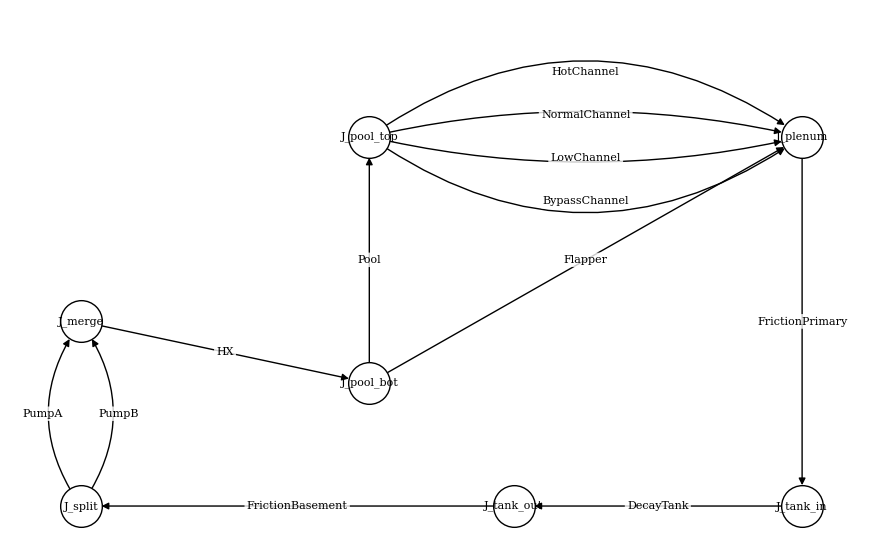

In [5]:
p_ref = p.p_surface + float(light_water.density(p.hx_outlet)) * g * p.core_depth

fg = FlowGraph(
    flow_edge((j_top, j_plenum), channels["hot"], signify=float(CORE["hot"].plates)),
    flow_edge((j_top, j_plenum), channels["normal"], signify=float(CORE["normal"].plates)),
    flow_edge((j_top, j_plenum), channels["low"], signify=float(CORE["low"].plates)),
    flow_edge((j_top, j_plenum), channels["bypass"], signify=float(CORE["bypass"].plates)),
    flow_edge((j_bot, j_top), pool),
    flow_edge((j_bot, j_plenum), flapper),
    flow_edge((j_plenum, j_tank_in), *primary),
    flow_edge((j_tank_in, j_tank_out), tank),
    flow_edge((j_tank_out, j_split), *basement),
    flow_edge((j_split, j_merge), pumps["A"], pump_curves["A"], flywheels["A"], valves["A"]),
    flow_edge((j_split, j_merge), pumps["B"], pump_curves["B"], flywheels["B"], valves["B"]),
    flow_edge((j_merge, j_bot), hx, hx_loss, *riser, ref_mdot_for=(flapper, trip)),
    inertial_comps=[*flywheels.values(), *channels.values(), pool, tank],
    k_constructor=KirchhoffWDerivatives,
    abs_pressure_comps=[channels[k] for k in HEATED],
    funcs={flapper: {"t": identity}, trip: {"t": identity}},
    reference_node=(j_top, p_ref),
)
K = fg.kirchhoff
check_gravity_mismatch(K)
print(f"pressure at the pool top: {p_ref / 1e5:.4f} bar")

fig, ax = plt.subplots(figsize=(11, 7))
draw(K, ax=ax)
plt.show()

## Plates on channels

The flow graph knows the channels but not the plates. `symmetric_plate` couples a channel to its plate as if each surrounded the other on both sides, which is how a channel between two identical plates sees them: the plate heats the channel through both walls, and the channel cools both faces of the plate. For the thermal-hydraulic steady state each plate is fed a constant `power`, the full core power, of which its `share` keeps its own fraction. Adding the three plate graphs to the flow graph's aggregator gives the complete thermal-hydraulic system, and `report` lists what each calculation still needs; the **Missing** column is empty.

In [6]:
agr = fg.aggregator
for k in HEATED:
    agr = agr + symmetric_plate(channels[k], fuels[k], funcs={fuels[k]: {"power": P0}}).to_aggregator()
report(agr)

Contains 620 Equations, 40 Nodes, 150 Edges.

| Calculation | Type | Equation No. | Unset | Set Externally | Missing |
| :---------- | :--- | :----------- | :---- | :------------- | :------ |
| J_pool_top | Junction | 0 - 1 |  |  |  |
| HotChannel | ChannelAndContacts | 1 - 32 |  |  |  |
| J_plenum | Junction | 32 - 33 |  |  |  |
| NormalChannel | ChannelAndContacts | 33 - 64 |  |  |  |
| LowChannel | ChannelAndContacts | 64 - 95 |  |  |  |
| BypassChannel | Channel | 95 - 106 | T_left, T_right, h_left, h_right |  |  |
| FrictionPrimary | Friction | 106 - 108 |  |  |  |
| BendPrimary0 | Bend | 108 - 110 |  |  |  |
| BendPrimary1 | Bend | 110 - 112 |  |  |  |
| GravityPrimary | Gravity | 112 - 114 |  |  |  |
| J_tank_in | Junction | 114 - 115 |  |  |  |
| J_pool_bot | Junction | 115 - 116 |  |  |  |
| Pool | Channel | 116 - 127 | T_left, T_right, h_left, h_right |  |  |
| Flapper | Flapper | 127 - 129 |  | t |  |
| DecayTank | Channel | 129 - 135 | T_left, T_right, h_left, h_right |  |  |
| J_tank_out | Junction | 135 - 136 |  |  |  |
| FrictionBasement | Friction | 136 - 138 |  |  |  |
| BendBasement0 | Bend | 138 - 140 |  |  |  |
| GravityBasement | Gravity | 140 - 142 |  |  |  |
| J_split | Junction | 142 - 143 |  |  |  |
| PumpA | Pump | 143 - 145 | pressure, mdot0 |  |  |
| PumpCurveA | Friction | 145 - 147 |  |  |  |
| FlywheelA | Inertia | 147 - 149 |  |  |  |
| ValveA | CheckValve | 149 - 151 |  |  |  |
| J_merge | Junction | 151 - 152 |  |  |  |
| PumpB | Pump | 152 - 154 | pressure, mdot0 |  |  |
| PumpCurveB | Friction | 154 - 156 |  |  |  |
| FlywheelB | Inertia | 156 - 158 |  |  |  |
| ValveB | CheckValve | 158 - 160 |  |  |  |
| HX | HeatExchanger | 160 - 162 |  |  |  |
| HXLoss | Friction | 162 - 164 |  |  |  |
| FrictionRiser | Friction | 164 - 166 |  |  |  |
| BendRiser0 | Bend | 166 - 168 |  |  |  |
| BendRiser1 | Bend | 168 - 170 |  |  |  |
| GravityRiser | Gravity | 170 - 172 |  |  |  |
| Kirchhoff | KirchhoffWDerivatives | 172 - 199 |  |  |  |
| Trip | LowFlowTrip | 199 - 200 |  | t |  |
| HotFuel | Fuel | 200 - 340 | T_top, T_bottom, h_top, h_bottom | power |  |
| NormalFuel | Fuel | 340 - 480 | T_top, T_bottom, h_top, h_bottom | power |  |
| LowFuel | Fuel | 480 - 620 | T_top, T_bottom, h_top, h_bottom | power |  |


## A first solve

A steady solve needs a starting point, and for this loop a rough one is enough: every temperature at the heat-exchanger outlet, every pressure drop zero, heat-transfer coefficients of 1000 W/m²K, and flows set by the kind of edge: 0.5 kg/s through each core channel (one plate's flow), the full core flow through the pool and the pipes, half of it through each pump leg, and nothing through the flapper. The Kirchhoff calculation's flows and pressures are set on its own vector, which `K.save` turns into a state, and `K.component_edge` names the edge a component sits on. This is the example package's ballpark guess.

`steady` is `solve_steady` with the analytic algebraic Jacobian. `steady_checks` then compares the solution with estimates one can make by hand, the same checks the next page discusses: each heated channel's outlet temperature against the energy balance, the flow split against the turbulent gap law, and the pump heads. It reads the components through a dictionary of references.

In [7]:
non_kirchhoff = [n for n in agr.graph if n is not K]
k_vector = np.zeros(len(K))
k_vector[K.variables_by_type["mdot"]] = total
k_vector[K.variables_by_type["abs_pressure"]] = p_ref
k_state = K.save(k_vector)
for ch in channels.values():
    k_state[K.component_edge(ch)] = PER_PLATE_REFERENCE
k_state[K.component_edge(pool)] = total
k_state[K.component_edge(flapper)] = 0.0
for leg in "AB":
    k_state[K.component_edge(pumps[leg])] = total / 2
ballpark = State.merge(
    State.uniform(non_kirchhoff, p.hx_outlet, "T_cool", "T", "T_wall_left", "T_wall_right", "Tin"),
    State.uniform(non_kirchhoff, 1e3, "h_left", "h_right"),
    State.uniform(non_kirchhoff, 0.0, "pressure", "flag"),
    {K.name: k_state},
)

y_th = steady(agr, agr.load(ballpark))

refs = {"params": p, "channels": channels, "fuels": fuels, "pool": pool, "pumps": pumps, "power": P0}
chk = steady_checks(agr, K, refs, y_th)
print(f"core inlet temperature:         {chk['T_in']:.2f} °C")
print(f"worst outlet temperature error: {chk['T_out_error_max']:.4f} K")
print(f"worst split error:              {100 * chk['split_error_max']:.2f} %")
print(f"pool flow:                      {chk['pool_flow']:.1f} kg/s")
for leg, head in chk["heads"].items():
    print(f"pump {leg} head:                    {head / 1e5:.3f} bar")

core inlet temperature:         38.00 °C
worst outlet temperature error: 0.0044 K
worst split error:              3.39 %
pool flow:                      241.5 kg/s
pump A head:                    1.278 bar
pump B head:                    1.278 bar


## Attaching the kinetics

The solve lands where the hand estimates put it: the outlet temperatures within about 0.004 K of the energy balance, the per-plate flows within about 3.4 % of the gap law, and both pumps at about 1.28 bar. With the thermal-hydraulics solved, the constant power gives way to point kinetics. `PointKineticsWInput` takes six delayed-neutron groups, a generation time of 50 µs, temperature feedback and a reactivity controller. The feedback is a reactivity per kelvin on every coolant cell and every meat cell. The core's coefficients, -1e-4 per K for the coolant and -2e-5 per K for the fuel, are split between the groups by plate count times peaking factor, and within a group evenly over its cells. The reference temperatures are the solved ones, so the feedback is zero at the operating point and the reactor starts critical. The controller reads the rods' reactivity from the trip sensor.

The kinetics node is a single calculation, and its links are added by hand in a `CalculationGraph`: it reads the temperatures `T` of the heated channels and plates and feeds each plate its `power`. Besides the fission power it takes a `power_input`, the decay heat, which counts from the trip; at the operating point it is 6.6 % of the power. The plates are attached with `symmetric_plate` again, this time without a constant power, and the new graph is added to the same flow graph's aggregator.

In [8]:
st_th = agr.save(y_th)
weight_sum = sum(grp.plates * grp.factor for grp in CORE.values())
temp_worth, ref_temp = {}, {}
for k in HEATED:
    fraction = p.feedback_scale * CORE[k].plates * CORE[k].factor / weight_sum
    temp_worth[channels[k]] = np.full(Z_N, p.coolant_worth * fraction / Z_N)
    temp_worth[fuels[k]] = np.full(Z_N * FUEL_N, p.fuel_worth * fraction / (Z_N * FUEL_N))
    ref_temp[channels[k]] = np.asarray(st_th[channels[k].name]["T_cool"], dtype=float).copy()
    meat = np.asarray(fuels[k].meat, dtype=bool).reshape(-1)
    ref_temp[fuels[k]] = np.asarray(st_th[fuels[k].name]["T"]).reshape(-1)[meat]

controls = ReactivityController(input_reactivity=lambda state, t_state, t: trip.rho(t))
pk = PointKineticsWInput(generation_time=GENERATION_TIME, delayed_neutron_fractions=BETA,
                         delayed_groups_decay_rates=LAMBDA, temp_worth=temp_worth, ref_temp=ref_temp,
                         controls=controls, name="PK")

In [9]:
dh = decay_heat(P0)
kinetics = CalculationGraph.from_decoupled(
    pk, funcs={pk: {"t": identity, "power_input": lambda t: dh(max(t - trip.t_trip, 0.0))}})
for k in HEATED:
    kinetics = kinetics + symmetric_plate(channels[k], fuels[k])
    kinetics.graph.add_edge(channels[k], pk, variables=("T",))
    kinetics.graph.add_edge(fuels[k], pk, variables=("T",))
    kinetics.graph.add_edge(pk, fuels[k], variables=("power",))
agr_k = fg.aggregator + kinetics.to_aggregator()

y = agr_k.load(State.merge(st_th, point_kinetics_steady_state(pk, P0, power_input=dh(0.0))))
pk_state = agr_k.save(y, t=0.0)["PK"]
print(f"power:          {float(pk_state['power']) / 1e6:.3f} MW")
print(f"decay heat:     {dh(0.0) / 1e6:.3f} MW")
print(f"reactivity:     {float(pk_state['reactivity']):.1e}")
print(f"steady residual: {np.linalg.norm(agr_k.compute(y, 0.0)):.1e}")

power:          10.000 MW
decay heat:     0.660 MW
reactivity:     0.0e+00
steady residual: 1.7e-07


## The same loop as `build`

The kinetics node reads the full 10 MW, of which 0.66 MW is decay heat, at zero reactivity, and the residual of about 2e-7 is what the steady solve left. `agr_k` and `y` are the system and state `operating_point` produces for these parameters, and `build(p, kinetics=True, ref_state=st_th)` builds the same system in one call. The check below builds it that way and compares: the two aggregators lay out the same calculations, by name, on the same slices of the state vector, and the state solved on this page, loaded into the one from `build`, leaves it the same steady residual. From here on the examples use `build` and `operating_point`; the next page, [A Pool Reactor for Loss-of-Flow Analysis](LOFAPoolReactor.ipynb), takes the operating point apart and checks it.

In [10]:
agr_ref, _, _ = build(p, kinetics=True, ref_state=st_th)
same_layout = [(c.name, s) for c, s in agr_k.sections.items()] == [(c.name, s) for c, s in agr_ref.sections.items()]
y_ref = agr_ref.load(agr_k.save(y))
print(f"same layout: {same_layout}")
print(f"steady residual here {np.linalg.norm(agr_k.compute(y, 0.0)):.3e}, in build's {np.linalg.norm(agr_ref.compute(y_ref, 0.0)):.3e}")

same layout: True
steady residual here 1.715e-07, in build's 1.715e-07
